# Lista 7 — Perceptron e Backpropagation
**Curso:** Ciência da Computação · **Disciplina:** Inteligência Artificial  
**Professora:** Cristiane Neri Nobre · **Entrega:** 14/11 · **Valor:** 4 pontos

## Execução e declaração de uso de IA
Neste notebook, reuni o código, as tabelas, os gráficos e a análise dos resultados. Para executar, coloque `titanic completo.csv` na pasta de trabalho do notebook e execute as células em ordem. No Colab, adicione o CSV pelo painel **Arquivos** antes de usar **Executar tudo**. Localmente, o código também procura a base nas pastas das listas anteriores. Não é necessário instalar bibliotecas de aprendizado de máquina.

**Uso de IA no texto:** usei o Codex (OpenAI) como apoio na elaboração das explicações, na análise dos resultados e na conclusão. **Uso de IA no código:** usei a ferramenta como apoio na implementação dos modelos, no pré-processamento, nos experimentos, nos gráficos e nas verificações. Indiquei essa assistência nas células de código.

Usei somente **NumPy, Pandas e Matplotlib** para os cálculos e gráficos, além de `pathlib`, da biblioteca padrão, para localizar o CSV. Fixei a semente com `np.random.seed` em cada experimento. Não utilizei scikit-learn, TensorFlow, PyTorch ou imbalanced-learn.

In [1]:
# Usei o Codex (OpenAI) como apoio na elaboração desta célula.
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
plt.rcParams.update({'figure.figsize': (7, 4), 'axes.grid': True, 'grid.alpha': 0.2})
pd.set_option('display.max_columns', 20)
print('NumPy:', np.__version__, '| Pandas:', pd.__version__)
X_logico = np.array([[0, 0], [0, 1], [1, 0], [1, 1]], dtype=float)
alvos = {'AND': np.array([0, 0, 0, 1]), 'OR': np.array([0, 1, 1, 1]),
         'XOR': np.array([0, 1, 1, 0])}
display(pd.DataFrame({'x1': X_logico[:, 0], 'x2': X_logico[:, 1], **alvos}))

NumPy: 2.5.2 | Pandas: 3.0.5


,x1,x2,AND,OR,XOR
0,0.0,0.0,0,0,0
1,0.0,1.0,0,1,1
2,1.0,0.0,0,1,1
3,1.0,1.0,1,1,0


## 1. Perceptron: implementação e estado inicial
O bias é o primeiro peso e recebe uma entrada constante igual a 1. Cada passagem pelos dados mantém a ordem fornecida. O histórico registra os erros **durante** a época (cada erro provoca uma atualização), os pesos ao final e a acurácia recalculada com esses pesos. Esses dois tipos de medida não são equivalentes, pois os pesos mudam durante a passagem.

A parada antecipada exige uma época inteira sem atualizações. No XOR, mantive as 100 épocas. Os experimentos AND/OR e as variações de taxa partem exatamente dos mesmos pesos.

Pesos iniciais [w0, w1, w2]: [-0.25091976  0.90142861  0.46398788]
Reta inicial: -0.250920 + 0.901429 x1 + 0.463988 x2 = 0


,x1,x2,AND,z,ŷ
0,0.0,0.0,0,-0.250920,0
1,0.0,1.0,0,0.213068,1
2,1.0,0.0,0,0.650509,1
3,1.0,1.0,1,1.114497,1


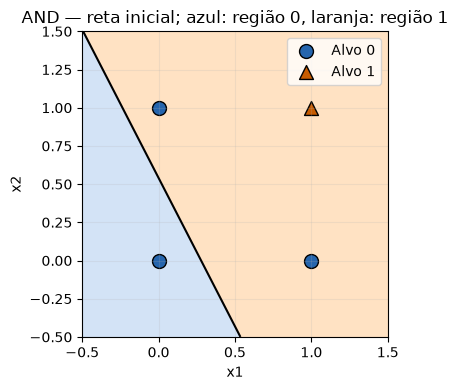

In [2]:
# Usei o Codex (OpenAI) como apoio na elaboração desta célula.
class Perceptron:
    def __init__(self, eta=0.1, max_epocas=100, seed=42, pesos_iniciais=None):
        self.eta, self.max_epocas, self.seed = eta, max_epocas, seed
        self.pesos_iniciais = pesos_iniciais

    def fit(self, X, y, parar_sem_erros=True):
        X, y = np.asarray(X, float), np.asarray(y, int)
        np.random.seed(self.seed)
        self.w = (np.random.uniform(-1, 1, X.shape[1] + 1) if self.pesos_iniciais is None
                  else np.array(self.pesos_iniciais, dtype=float, copy=True))
        self.w_inicial = self.w.copy()
        Xb = np.column_stack([np.ones(len(X)), X])
        registros = []
        self.atualizacoes = 0
        self.convergiu = False
        for epoca in range(1, self.max_epocas + 1):
            erros = 0
            for xi, d in zip(Xb, y):
                previsto = int(xi @ self.w >= 0)
                erro = d - previsto
                if erro != 0:
                    self.w += self.eta * erro * xi
                    erros += 1
            self.atualizacoes += erros
            registros.append({'epoca': epoca, 'erros': erros,
                'acuracia': np.mean(self.predict(X) == y),
                **{f'w{i}': w for i, w in enumerate(self.w)}})
            if erros == 0:
                self.convergiu = True
                if parar_sem_erros:
                    break
        self.historico = pd.DataFrame(registros)
        self.epocas = len(registros)
        return self

    def decision_function(self, X):
        X = np.asarray(X, float)
        return self.w[0] + X @ self.w[1:]

    def predict(self, X):
        return (self.decision_function(X) >= 0).astype(int)

np.random.seed(SEED)
w_inicial = np.random.uniform(-1, 1, 3)
z_inicial = w_inicial[0] + X_logico @ w_inicial[1:]
print('Pesos iniciais [w0, w1, w2]:', w_inicial)
print(f'Reta inicial: {w_inicial[0]:.6f} + {w_inicial[1]:.6f} x1 + {w_inicial[2]:.6f} x2 = 0')
display(pd.DataFrame({'x1': X_logico[:, 0], 'x2': X_logico[:, 1],
    'AND': alvos['AND'], 'z': z_inicial, 'ŷ': (z_inicial >= 0).astype(int)}))

def fronteira(ax, w, y, titulo):
    eixo = np.linspace(-0.5, 1.5, 250)
    xx, yy = np.meshgrid(eixo, eixo)
    z = w[0] + w[1] * xx + w[2] * yy
    ax.contourf(xx, yy, (z >= 0).astype(int), levels=[-0.5, 0.5, 1.5],
                colors=['#c9ddf4', '#ffdbb5'], alpha=0.8)
    if z.min() < 0 < z.max():
        ax.contour(xx, yy, z, levels=[0], colors='black', linewidths=1.5)
    for classe, cor, marcador in [(0, '#2565ad', 'o'), (1, '#c75c00', '^')]:
        pts = X_logico[y == classe]
        ax.scatter(pts[:, 0], pts[:, 1], c=cor, marker=marcador, s=100,
                   edgecolors='black', label=f'Alvo {classe}')
    ax.set(xlabel='x1', ylabel='x2', title=titulo, xlim=(-0.5, 1.5), ylim=(-0.5, 1.5))
    ax.legend(); ax.set_aspect('equal')

fig, ax = plt.subplots()
fronteira(ax, w_inicial, alvos['AND'], 'AND — reta inicial; azul: região 0, laranja: região 1')
plt.tight_layout(); plt.show()

## 2. AND e OR: treinamento e efeito da taxa
Além dos pesos finais, a tabela informa atualizações, épocas (incluindo a época de confirmação sem erros) e acurácia. A comparação de η mantém pesos, ordem e limite de épocas fixos.

,função,eta,w0,w1,w2,atualizações,épocas,acurácia,convergiu
0,AND,0.1,-0.65092,0.601429,0.363988,4,4,1.0,True
1,AND,0.5,-1.25092,0.901429,0.463988,6,4,1.0,True
2,OR,0.1,-0.25092,0.901429,0.463988,0,1,1.0,True
3,OR,0.5,-0.25092,0.901429,0.463988,0,1,1.0,True


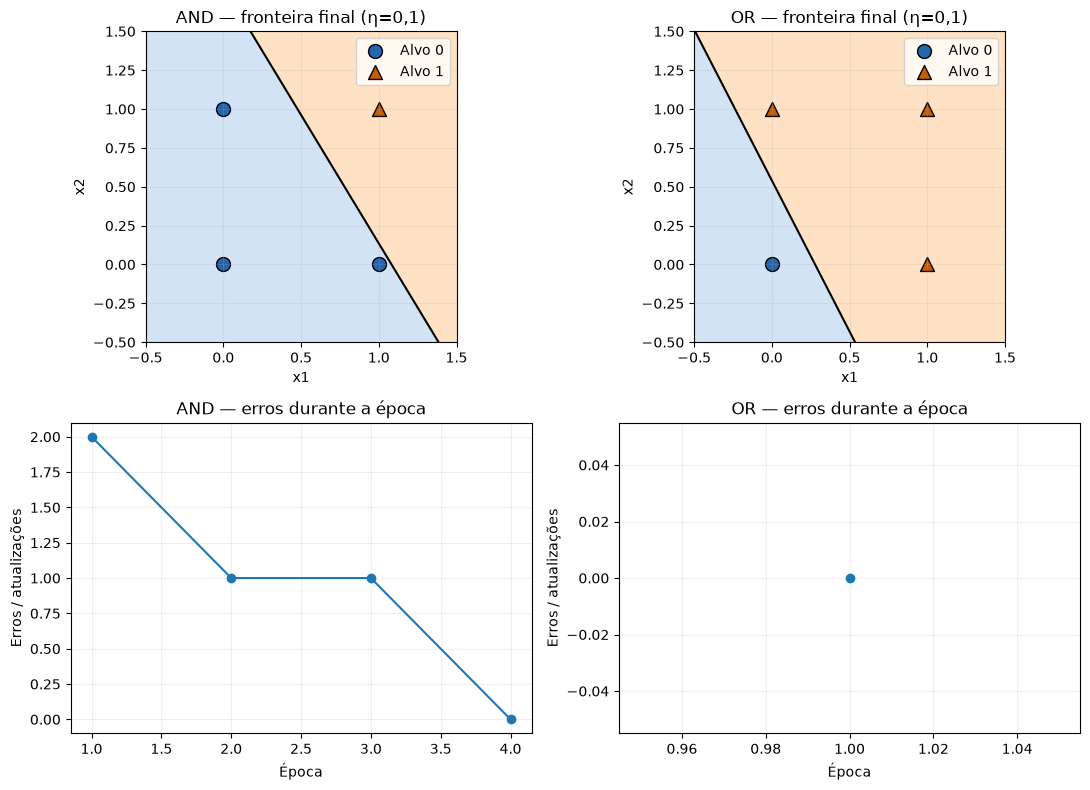

AND: η=0,1 → 4 atualizações; η=0,5 → 6. O número mudou.
OR: η=0,1 → 0 atualizações; η=0,5 → 0. O número não mudou nesta execução.


In [3]:
# Usei o Codex (OpenAI) como apoio na elaboração desta célula.
modelos_logicos, registros = {}, []
for nome in ['AND', 'OR']:
    for eta in [0.1, 0.5]:
        modelo = Perceptron(eta=eta, pesos_iniciais=w_inicial).fit(X_logico, alvos[nome])
        modelos_logicos[nome, eta] = modelo
        registros.append({'função': nome, 'eta': eta, 'w0': modelo.w[0],
            'w1': modelo.w[1], 'w2': modelo.w[2], 'atualizações': modelo.atualizacoes,
            'épocas': modelo.epocas, 'acurácia': np.mean(modelo.predict(X_logico) == alvos[nome]),
            'convergiu': modelo.convergiu})
resumo_perceptron = pd.DataFrame(registros)
display(resumo_perceptron)
fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for col, nome in enumerate(['AND', 'OR']):
    m = modelos_logicos[nome, 0.1]
    fronteira(axes[0, col], m.w, alvos[nome], f'{nome} — fronteira final (η=0,1)')
    axes[1, col].plot(m.historico.epoca, m.historico.erros, 'o-')
    axes[1, col].set(title=f'{nome} — erros durante a época', xlabel='Época', ylabel='Erros / atualizações')
plt.tight_layout(); plt.show()
for nome in ['AND', 'OR']:
    a, b = modelos_logicos[nome, 0.1], modelos_logicos[nome, 0.5]
    print(f'{nome}: η=0,1 → {a.atualizacoes} atualizações; η=0,5 → {b.atualizacoes}. '
          + ('O número mudou.' if a.atualizacoes != b.atualizacoes else 'O número não mudou nesta execução.'))
assert all(m.convergiu and np.mean(m.predict(X_logico) == alvos[n]) == 1
           for (n, eta), m in modelos_logicos.items())

**Respostas.** As retas finais são diferentes porque AND deve deixar apenas (1,1) na região positiva, enquanto OR deve incluir também (0,1) e (1,0). As fronteiras não são únicas. A taxa altera o tamanho das atualizações em relação aos pesos iniciais e pode alterar a trajetória e a quantidade de erros, como quantificado acima. Não se pode concluir que multiplicar η por cinco sempre diminui o número de atualizações por cinco.

Nesta inicialização, OR já começa corretamente separado e termina com zero atualizações. Isso é um resultado válido, não uma ausência de treinamento: a primeira época confirma zero erros. Para AND, aumentar η de 0,1 para 0,5 aumentou as atualizações de 4 para 6.

## 3. Limitação do Perceptron no XOR
Executei 100 épocas para cada η, sem interpretar o limite como convergência. A acurácia é verificada com os pesos finais **de cada uma das 100 épocas**, e não apenas na última.

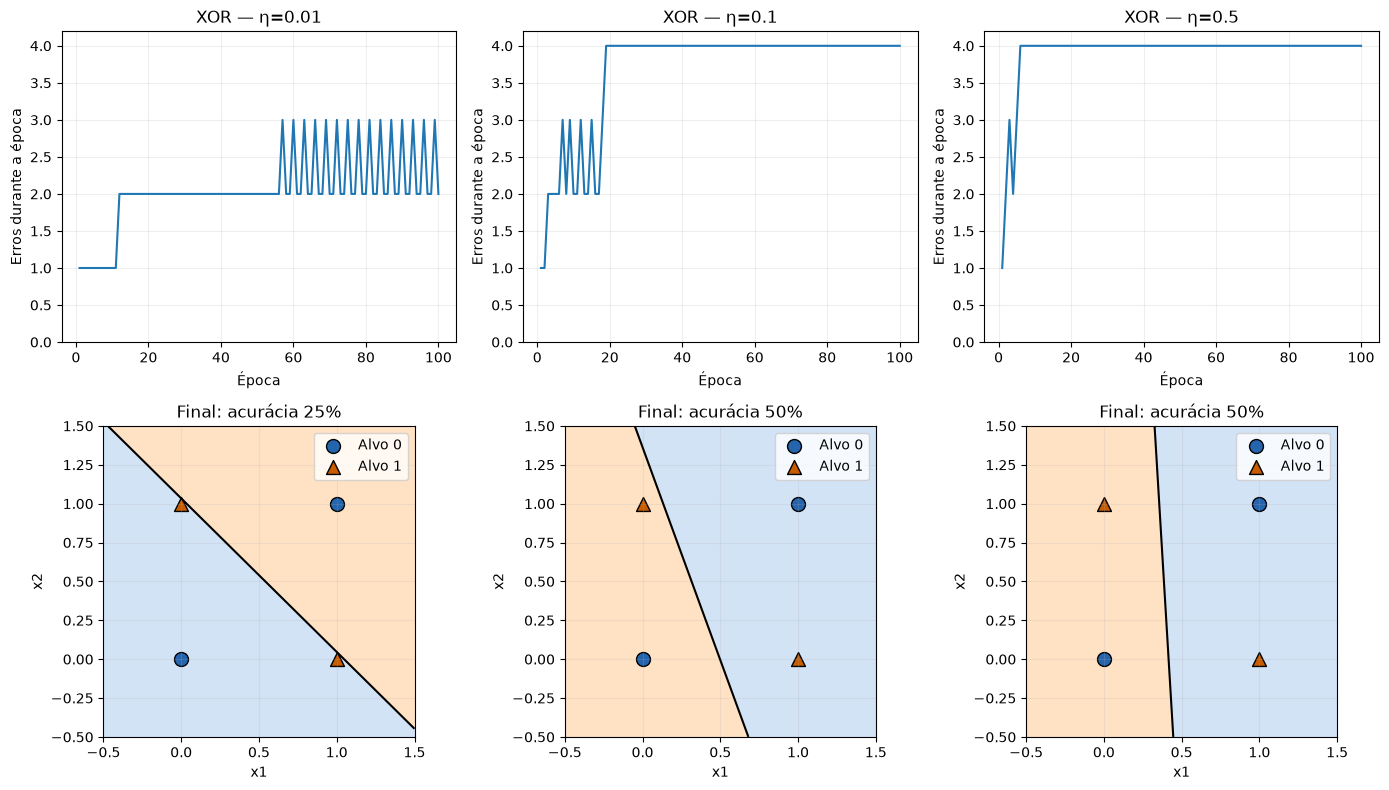

,eta,épocas,atualizações,acurácia final,maior acurácia nas épocas,épocas com 100%
0,0.01,100,204,0.25,0.75,0
1,0.10,100,367,0.50,0.75,0
2,0.50,100,391,0.50,0.50,0


In [4]:
# Usei o Codex (OpenAI) como apoio na elaboração desta célula.
modelos_xor, linhas_xor = {}, []
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for j, eta in enumerate([0.01, 0.1, 0.5]):
    m = Perceptron(eta=eta, pesos_iniciais=w_inicial).fit(X_logico, alvos['XOR'], parar_sem_erros=False)
    modelos_xor[eta] = m
    linhas_xor.append({'eta': eta, 'épocas': m.epocas, 'atualizações': m.atualizacoes,
        'acurácia final': m.historico.acuracia.iloc[-1],
        'maior acurácia nas épocas': m.historico.acuracia.max(),
        'épocas com 100%': int((m.historico.acuracia == 1).sum())})
    axes[0, j].plot(m.historico.epoca, m.historico.erros)
    axes[0, j].set(title=f'XOR — η={eta}', xlabel='Época', ylabel='Erros durante a época', ylim=(0, 4.2))
    fronteira(axes[1, j], m.w, alvos['XOR'], f'Final: acurácia {m.historico.acuracia.iloc[-1]:.0%}')
    assert m.epocas == 100 and (m.historico.acuracia < 1).all() and not m.convergiu
plt.tight_layout(); plt.show()
display(pd.DataFrame(linhas_xor))

**Respostas.** Os pontos positivos do XOR estão em cantos opostos do quadrado; os negativos ocupam a outra diagonal. O segmento entre os positivos e o segmento entre os negativos se cruzam em (0,5; 0,5), portanto seus fechos convexos se intersectam e nenhuma reta separa as classes. Algebricamente, seria necessário w₀ < 0, w₀+w₁ ≥ 0, w₀+w₂ ≥ 0 e w₀+w₁+w₂ < 0. Somar as desigualdades positivas implica w₀+w₁+w₂ ≥ −w₀ > 0: contradição. Alterar η não muda a família de fronteiras lineares. Uma camada oculta com ativação não linear permite combinar fronteiras e resolver o problema.

## 4. Backpropagation implementado do zero
A rede tem bias nas duas camadas. No XOR é **2–2–1**, com sigmoide em todos os neurônios, η=0,5, 10.000 épocas e SGD (uma atualização por instância), na ordem fixa da tabela. Pesos e biases começam em U(−0,5; 0,5), evitando simetria entre unidades.

Forward: zₕ = XW₁+b₁, h = σ(zₕ), zₒ = hW₂+b₂, y = σ(zₒ).

Backward: δₒ=(d−y)y(1−y), δₕ=h(1−h)(δₒW₂ᵀ). Calculei ambos os deltas **antes** de atualizar qualquer peso. Para um batch de B exemplos, ΔW₁=ηXᵀδₕ/B e ΔW₂=ηhᵀδₒ/B; biases recebem a média dos deltas.

A função otimizada é **E = (1/2)·MSE**, para corresponder exatamente aos deltas pedidos. Os gráficos mostram o **MSE completo**, medido após cada época. A verificação numérica diferencia E, não MSE; caso contrário haveria um fator 2.

In [5]:
# Usei o Codex (OpenAI) como apoio na elaboração desta célula.
class RedeNeural:
    def __init__(self, entradas, ocultos, eta=0.1, seed=42):
        np.random.seed(seed)
        self.eta, self.seed = eta, seed
        self.W1 = np.random.uniform(-0.5, 0.5, (entradas, ocultos))
        self.b1 = np.random.uniform(-0.5, 0.5, (1, ocultos))
        self.W2 = np.random.uniform(-0.5, 0.5, (ocultos, 1))
        self.b2 = np.random.uniform(-0.5, 0.5, (1, 1))

    @staticmethod
    def sigmoid(z):
        # Usei esta forma da sigmoide para evitar overflow sem precisar de clipping.
        e = np.exp(-np.abs(z))
        return np.where(z >= 0, 1 / (1 + e), e / (1 + e))

    def forward(self, X):
        z_h = np.asarray(X, float) @ self.W1 + self.b1
        h = self.sigmoid(z_h)
        z_o = h @ self.W2 + self.b2
        y = self.sigmoid(z_o)
        return z_h, h, z_o, y

    def backward(self, X, d):
        X, d = np.asarray(X, float), np.asarray(d, float).reshape(-1, 1)
        z_h, h, z_o, y = self.forward(X)
        delta_o = (d - y) * y * (1 - y)
        delta_h = h * (1 - h) * (delta_o @ self.W2.T)
        # Calculei os gradientes de E = MSE/2 para manter a atualização η·δ·entrada.
        grad = {'W1': -(X.T @ delta_h) / len(X), 'b1': -delta_h.mean(axis=0, keepdims=True),
                'W2': -(h.T @ delta_o) / len(X), 'b2': -delta_o.mean(axis=0, keepdims=True)}
        return grad, delta_h, delta_o

    def predict_proba(self, X):
        return self.forward(X)[-1].ravel()

    def predict(self, X):
        return (self.predict_proba(X) >= 0.5).astype(int)

    def mse(self, X, y):
        return np.mean((np.asarray(y).ravel() - self.predict_proba(X)) ** 2)

    def fit(self, X, y, epocas, batch_size, embaralhar=False, avaliacao=None):
        np.random.seed(self.seed)
        X, y = np.asarray(X, float), np.asarray(y, float)
        self.erro_treino, self.erro_teste, self.acuracias = [], [], []
        for _ in range(epocas):
            ordem = np.random.permutation(len(X)) if embaralhar else np.arange(len(X))
            for inicio in range(0, len(X), batch_size):
                idx = ordem[inicio:inicio + batch_size]
                grad, _, _ = self.backward(X[idx], y[idx])
                for nome, valor in grad.items():
                    setattr(self, nome, getattr(self, nome) - self.eta * valor)
            self.erro_treino.append(self.mse(X, y))
            self.acuracias.append(np.mean(self.predict(X) == y))
            if avaliacao is not None:
                self.erro_teste.append(self.mse(*avaliacao))
        return self

# Usei a entrada (0,1) para mostrar o forward, os deltas e uma atualização.
demo = RedeNeural(2, 2, eta=0.5, seed=SEED)
xi, di = X_logico[1:2], alvos['XOR'][1:2]
zh, h, zo, saida = demo.forward(xi)
grad, dh, do = demo.backward(xi, di)
print('Entrada:', xi, '| alvo:', di)
print('z ocultos:', zh, '| h:', h, '| z saída:', zo, '| y:', saida)
print('δ ocultos:', dh, '| δ saída:', do)
for nome, g in grad.items():
    antes = getattr(demo, nome).copy()
    setattr(demo, nome, antes - demo.eta * g)
    print(nome, '\nAntes:', antes, '\nΔ:', -demo.eta * g, '\nDepois:', getattr(demo, nome))

Entrada: [[0. 1.]] | alvo: [1]
z ocultos: [[-0.11198742 -0.245347  ]] | h: [[0.47203237 0.43896909]] | z saída: [[0.05325618]] | y: [[0.5133109]]
δ ocultos: [[-0.01339069  0.01096464]] | δ saída: [[0.12158604]]
W1 
Antes: [[-0.12545988  0.45071431]
 [ 0.23199394  0.09865848]] 
Δ: [[ 0.          0.        ]
 [-0.00669534  0.00548232]] 
Depois: [[-0.12545988  0.45071431]
 [ 0.2252986   0.10414081]]
b1 
Antes: [[-0.34398136 -0.34400548]] 
Δ: [[-0.00669534  0.00548232]] 
Depois: [[-0.3506767  -0.33852316]]
W2 
Antes: [[-0.44191639]
 [ 0.36617615]] 
Δ: [[0.02869627]
 [0.02668626]] 
Depois: [[-0.41322011]
 [ 0.3928624 ]]
b2 
Antes: [[0.10111501]] 
Δ: [[0.06079302]] 
Depois: [[0.16190803]]


,parâmetro,analítico,diferença finita,diferença absoluta
0,"W1(0, 0)",-0.000523,-0.000523,1.412468e-12
1,"W2(0, 0)",0.002295,0.002295,1.772926e-12
2,"b1(0, 0)",-0.000640,-0.000640,2.034470e-12
3,"b2(0, 0)",0.005540,0.005540,5.652865e-13


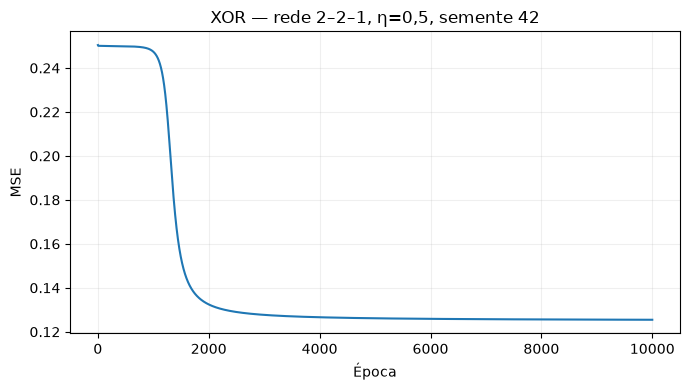

,x1,x2,alvo,saída sigmoide,"classe (≥ 0,5)"
0,0.0,0.0,0,0.016649,0
1,0.0,1.0,1,0.491586,0
2,1.0,0.0,1,0.981154,1
3,1.0,1.0,0,0.492708,0


Acurácia final: 75%


,semente,MSE final,acurácia final,convergiu (critério da tarefa)
0,0,0.000342,1.0,True
1,1,0.000315,1.0,True
2,2,0.000335,1.0,True
3,3,0.000331,1.0,True
4,4,0.000305,1.0,True


Convergiram: 5 de 5 sementes.


,x1,x2,alvo,saída semente 0,saída semente 1,saída semente 2,saída semente 3,saída semente 4
0,0.0,0.0,0,0.016594,0.015949,0.016444,0.016358,0.019290
1,0.0,1.0,1,0.982462,0.983165,0.982588,0.982734,0.983358
2,1.0,0.0,1,0.982381,0.983071,0.982595,0.982668,0.983354
3,1.0,1.0,0,0.021760,0.020891,0.021541,0.021389,0.017189


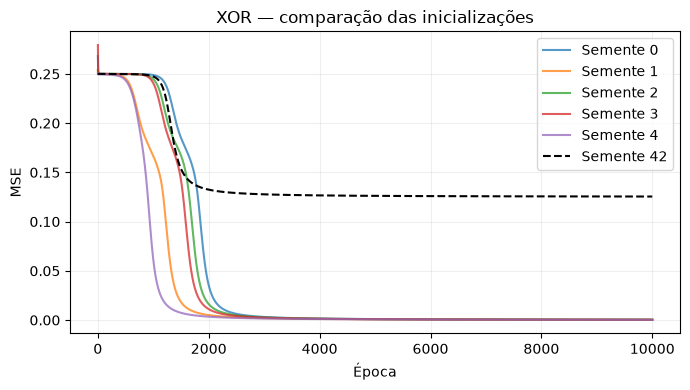

In [6]:
# Usei o Codex (OpenAI) como apoio na elaboração desta célula.
# Conferi o gradiente antes do treino para evitar comparar valores já saturados.
checagem = RedeNeural(2, 2, eta=0.5, seed=SEED)
grad, _, _ = checagem.backward(X_logico, alvos['XOR'])
epsilon = 1e-5
linhas_gradiente = []
for nome, indice in [('W1', (0, 0)), ('W2', (0, 0)), ('b1', (0, 0)), ('b2', (0, 0))]:
    parametro = getattr(checagem, nome)
    original = parametro[indice]
    parametro[indice] = original + epsilon
    e_mais = 0.5 * checagem.mse(X_logico, alvos['XOR'])
    parametro[indice] = original - epsilon
    e_menos = 0.5 * checagem.mse(X_logico, alvos['XOR'])
    parametro[indice] = original
    numerico = (e_mais - e_menos) / (2 * epsilon)
    analitico = grad[nome][indice]
    diferenca = abs(analitico - numerico)
    linhas_gradiente.append({'parâmetro': f'{nome}{indice}', 'analítico': analitico,
                            'diferença finita': numerico, 'diferença absoluta': diferenca})
    assert diferenca < 1e-6
display(pd.DataFrame(linhas_gradiente))

rede_xor = RedeNeural(2, 2, eta=0.5, seed=SEED).fit(X_logico, alvos['XOR'], 10000, 1)
plt.plot(np.arange(1, 10001), rede_xor.erro_treino)
plt.xlabel('Época'); plt.ylabel('MSE'); plt.title('XOR — rede 2–2–1, η=0,5, semente 42')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'x1': X_logico[:, 0], 'x2': X_logico[:, 1], 'alvo': alvos['XOR'],
    'saída sigmoide': rede_xor.predict_proba(X_logico), 'classe (≥ 0,5)': rede_xor.predict(X_logico)}))
print(f'Acurácia final: {np.mean(rede_xor.predict(X_logico) == alvos["XOR"]):.0%}')

sementes = [0, 1, 2, 3, 4]
linhas_sementes = []
redes_sementes = {}
for seed in sementes:
    rede = RedeNeural(2, 2, eta=0.5, seed=seed).fit(X_logico, alvos['XOR'], 10000, 1)
    redes_sementes[seed] = rede
    acuracia = np.mean(rede.predict(X_logico) == alvos['XOR'])
    linhas_sementes.append({'semente': seed, 'MSE final': rede.erro_treino[-1],
        'acurácia final': acuracia, 'convergiu (critério da tarefa)': acuracia == 1.0})
resumo_sementes = pd.DataFrame(linhas_sementes)
display(resumo_sementes)
print(f'Convergiram: {int(resumo_sementes["convergiu (critério da tarefa)"].sum())} de 5 sementes.')
# Mostrei as saídas de todas as repetições para comparar os resultados no XOR.
saidas_repeticoes = pd.DataFrame({'x1': X_logico[:, 0], 'x2': X_logico[:, 1], 'alvo': alvos['XOR']})
for seed, rede in redes_sementes.items():
    saidas_repeticoes[f'saída semente {seed}'] = rede.predict_proba(X_logico)
display(saidas_repeticoes)
for seed, rede in redes_sementes.items():
    plt.plot(np.arange(1, 10001), rede.erro_treino, label=f'Semente {seed}', alpha=0.75)
plt.plot(np.arange(1, 10001), rede_xor.erro_treino, '--', color='black', label='Semente 42')
plt.xlabel('Época'); plt.ylabel('MSE'); plt.title('XOR — comparação das inicializações')
plt.legend(); plt.tight_layout(); plt.show()


**Critério e respostas.** Aqui “convergiu” significa classificar as quatro entradas corretamente **ao final das 10.000 épocas**, com limiar 0,5. Isso não afirma que o gradiente zerou nem que o erro atingiu zero. Todas as execuções mantêm o orçamento completo.

Quem representa o XOR é a **rede com camada oculta não linear**; o Backpropagation calcula os gradientes que permitem ajustá-la. Duas unidades ocultas transformam as entradas em características que a saída consegue separar. Sem ativação não linear, empilhar camadas continuaria equivalente a uma transformação linear. Sigmoides saturadas geram derivadas pequenas; a superfície de erro não convexa também apresenta regiões planas e soluções ruins. Inicialização, ordem das amostras, taxa e orçamento podem produzir trajetórias diferentes. Cinco sementes são uma verificação limitada, não garantia de convergência em toda inicialização.

**Resultado observado:** a execução principal, com semente 42, terminou com 75% de acurácia e duas saídas próximas de 0,5. As cinco repetições (sementes 0 a 4) chegaram a 100%. Mantive a execução que falhou, sem trocar sua semente para melhorar o resultado. São **5 de 5 repetições** bem-sucedidas, ou **5 de 6 execuções** se eu incluir a principal. A tabela adicional mostra as quatro saídas de cada repetição; as curvas contrastam o platô com as trajetórias bem-sucedidas.


## 5. Titanic: dados e decisões de pré-processamento
Utilizei a base das listas anteriores e apenas **pclass, sex, age, sibsp, parch e fare**. `survived` é o alvo. Campos como `boat` e `body`, conhecidos após o desastre, não entram no modelo.

1. Divisão estratificada 80/20, semente 42. Dentro de cada classe, embaralhei os índices e reservei aproximadamente 20% (arredondamento por classe) para teste.
2. Retomei a imputação de **média/moda da Lista 2**: média para age/fare, moda para pclass/sex/sibsp/parch. Todos os valores são estimados exclusivamente no treino.
3. Codifiquei sex como male=0 e female=1; pclass permanece ordinal. Padronizei as seis entradas pela média e desvio padrão populacional do treino original, após imputação. Desvio zero é substituído por 1.
4. Retomei **RandomUnderSampling da Lista 3**, agora implementado em NumPy: sorteei, sem reposição, a mesma quantidade de exemplos de cada classe no treino. A escolha preserva passageiros reais e evita gerar valores fracionários para categorias, mas descarta parte da classe majoritária. O teste conserva sua distribuição original.
5. Rede com 8 unidades ocultas, η=0,1, batch 32, 200 épocas, embaralhamento em cada época. As redes de 2 e 32 unidades usam os mesmos dados e parâmetros. O Perceptron recebe exatamente o mesmo treino balanceado e padronizado, η=0,1 e limite de 100 épocas. A referência majoritária é definida no **treino original**.

Os gráficos de teste são exigidos pelo enunciado: não usei seu mínimo para interromper treinamento nem escolher hiperparâmetros. A comparação entre larguras é descritiva; não constitui seleção independente de modelo.

In [7]:
# Usei o Codex (OpenAI) como apoio na elaboração desta célula.
candidatos = [Path('titanic completo.csv'), Path('../List02/titanic completo.csv'),
              Path('../List05/titanic completo.csv'), Path('Lists/List02/titanic completo.csv')]
caminho = next((p for p in candidatos if p.exists()), None)
if caminho is None:
    raise FileNotFoundError(
        'Arquivo titanic completo.csv não encontrado. Coloque o CSV na pasta de trabalho '
        'do notebook. No Colab, adicione o arquivo pelo painel Arquivos e execute novamente.'
    )
dados = pd.read_csv(caminho)
features = ['pclass', 'sex', 'age', 'sibsp', 'parch', 'fare']
assert set(features + ['survived']).issubset(dados.columns)
assert dados.survived.notna().all() and set(dados.survived.unique()) == {0, 1}
y_total = dados.survived.to_numpy(dtype=int)
print('Base:', caminho, '| linhas:', len(dados))
display(dados[features + ['survived']].isna().sum().rename('ausências').to_frame())

np.random.seed(SEED)
indices_treino, indices_teste = [], []
for classe in [0, 1]:
    indices = np.random.permutation(np.flatnonzero(y_total == classe))
    n_teste = int(round(0.2 * len(indices)))
    indices_teste.extend(indices[:n_teste])
    indices_treino.extend(indices[n_teste:])
indices_treino = np.random.permutation(indices_treino)
indices_teste = np.random.permutation(indices_teste)
y_treino, y_teste = y_total[indices_treino], y_total[indices_teste]
treino = dados.iloc[indices_treino][features].copy()
teste = dados.iloc[indices_teste][features].copy()
preenchimento = {c: (treino[c].mean() if c in ['age', 'fare'] else treino[c].mode().iloc[0])
                 for c in features}
display(pd.Series(preenchimento, name='valor de imputação (treino)').to_frame())

def codificar(frame):
    frame = frame.fillna(preenchimento).copy()
    frame['sex'] = frame['sex'].map({'male': 0, 'female': 1})
    return frame[features].to_numpy(dtype=float)

A, B = codificar(treino), codificar(teste)
media, desvio = A.mean(axis=0), A.std(axis=0)
desvio = np.where(desvio == 0, 1, desvio)
X_treino, X_teste = (A - media) / desvio, (B - media) / desvio
np.random.seed(SEED)
n_menor = min(np.sum(y_treino == c) for c in [0, 1])
idx_balanceado = np.concatenate([np.random.choice(np.flatnonzero(y_treino == c), n_menor, replace=False)
                                for c in [0, 1]])
np.random.shuffle(idx_balanceado)
X_balanceado, y_balanceado = X_treino[idx_balanceado], y_treino[idx_balanceado]
display(pd.DataFrame([{'conjunto': nome, 'n': len(y), 'classe 0': np.sum(y == 0),
    'classe 1': np.sum(y == 1), 'proporção classe 1': y.mean()}
    for nome, y in [('Treino original', y_treino), ('Treino balanceado', y_balanceado), ('Teste', y_teste)]]))
assert set(indices_treino).isdisjoint(indices_teste)
assert len(indices_treino) + len(indices_teste) == len(dados)
assert np.isfinite(X_treino).all() and np.isfinite(X_teste).all()
assert np.sum(y_balanceado == 0) == np.sum(y_balanceado == 1)

Base: ../List02/titanic completo.csv | linhas: 1309


,ausências
pclass,0
sex,0
age,263
sibsp,0
parch,0
fare,1
survived,0


,valor de imputação (treino)
pclass,3
sex,male
age,29.694604
sibsp,0
parch,0
fare,32.927154


,conjunto,n,classe 0,classe 1,proporção classe 1
0,Treino original,1047,647,400,0.382044
1,Treino balanceado,800,400,400,0.500000
2,Teste,262,162,100,0.381679


,neurônios ocultos,acurácia,precisão (1),revocação (1)
0,2,0.751908,0.666667,0.70
1,8,0.751908,0.669903,0.69
2,32,0.748092,0.663462,0.69


,modelo,acurácia,precisão (1),revocação (1)
0,Classe majoritária,0.618321,0.000000,0.00
1,Perceptron,0.702290,0.593220,0.70
2,Rede 6–8–1,0.751908,0.669903,0.69


Perceptron: épocas = 100 | atualizações = 25379 | convergiu = False


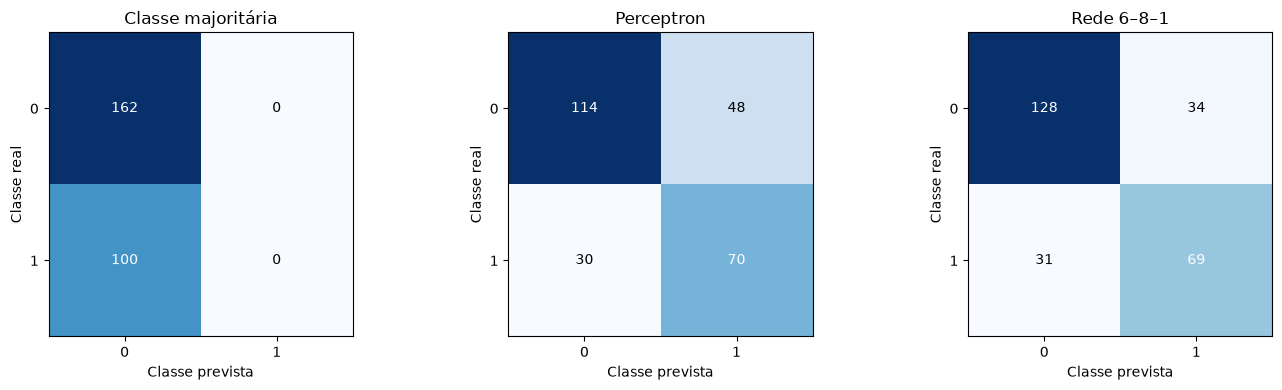

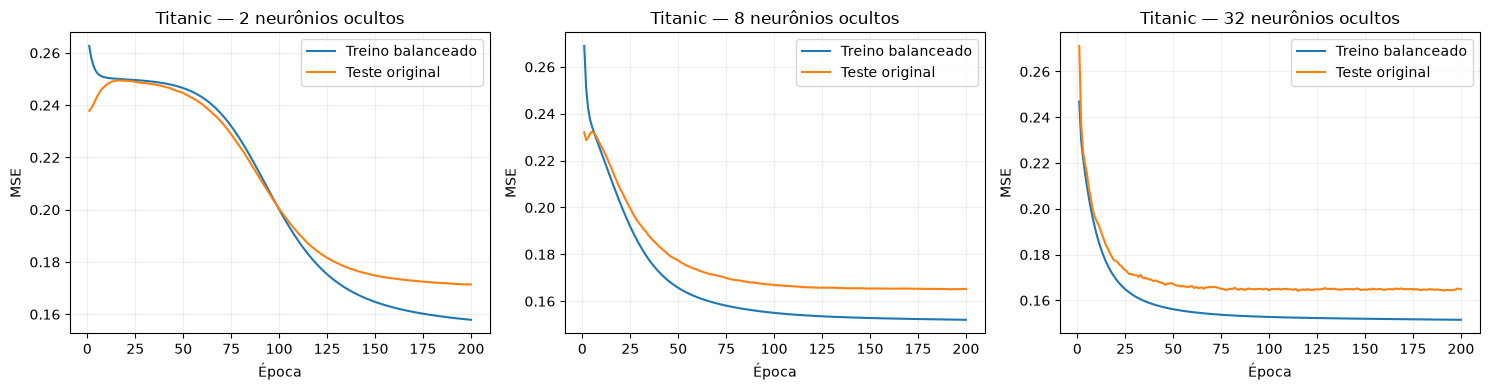

MSE final em treino original (rede 8): 0.1526558892755547
MSE final em treino balanceado (rede 8): 0.15207698533384773
MSE final em teste (rede 8): 0.1652272208496857


In [8]:
# Usei o Codex (OpenAI) como apoio na elaboração desta célula.
def metricas(y, previsto):
    matriz = np.zeros((2, 2), dtype=int)
    np.add.at(matriz, (np.asarray(y, int), np.asarray(previsto, int)), 1)
    tn, fp, fn, tp = matriz.ravel()
    return {'acurácia': (tn + tp) / matriz.sum(),
            'precisão (1)': tp / (tp + fp) if tp + fp else 0.0,
            'revocação (1)': tp / (tp + fn) if tp + fn else 0.0}, matriz

redes_titanic, linhas_larguras = {}, []
for ocultos in [2, 8, 32]:
    rede = RedeNeural(6, ocultos, eta=0.1, seed=SEED).fit(
        X_balanceado, y_balanceado, epocas=200, batch_size=32, embaralhar=True,
        avaliacao=(X_teste, y_teste))
    redes_titanic[ocultos] = rede
    met, _ = metricas(y_teste, rede.predict(X_teste))
    linhas_larguras.append({'neurônios ocultos': ocultos, **met})
resumo_larguras = pd.DataFrame(linhas_larguras)
display(resumo_larguras)

rede_titanic = redes_titanic[8]
perceptron_titanic = Perceptron(eta=0.1, max_epocas=100, seed=SEED).fit(X_balanceado, y_balanceado)
classe_majoritaria = int(np.argmax(np.bincount(y_treino)))
previsoes = {'Classe majoritária': np.full(len(y_teste), classe_majoritaria),
             'Perceptron': perceptron_titanic.predict(X_teste),
             'Rede 6–8–1': rede_titanic.predict(X_teste)}
linhas_metricas, matrizes = [], {}
for nome, pred in previsoes.items():
    met, matriz = metricas(y_teste, pred)
    linhas_metricas.append({'modelo': nome, **met})
    matrizes[nome] = matriz
resumo_titanic = pd.DataFrame(linhas_metricas)
display(resumo_titanic)
print('Perceptron: épocas =', perceptron_titanic.epocas,
      '| atualizações =', perceptron_titanic.atualizacoes, '| convergiu =', perceptron_titanic.convergiu)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, matriz) in zip(axes, matrizes.items()):
    ax.imshow(matriz, cmap='Blues')
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(matriz[i, j]), ha='center', va='center',
                    color='white' if matriz[i, j] > matriz.max()/2 else 'black')
    ax.set(title=nome, xlabel='Classe prevista', ylabel='Classe real', xticks=[0, 1], yticks=[0, 1])
    ax.grid(False)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (ocultos, rede) in zip(axes, redes_titanic.items()):
    # Balanceei somente o treino e mantive a distribuição original no teste.
    # Considerei essa diferença de distribuição na interpretação das curvas.
    ax.plot(np.arange(1, 201), rede.erro_treino, label='Treino balanceado')
    ax.plot(np.arange(1, 201), rede.erro_teste, label='Teste original')
    ax.set(title=f'Titanic — {ocultos} neurônios ocultos', xlabel='Época', ylabel='MSE')
    ax.legend()
plt.tight_layout(); plt.show()
print('MSE final em treino original (rede 8):', rede_titanic.mse(X_treino, y_treino))
print('MSE final em treino balanceado (rede 8):', rede_titanic.erro_treino[-1])
print('MSE final em teste (rede 8):', rede_titanic.erro_teste[-1])
assert all(len(r.erro_treino) == len(r.erro_teste) == 200 for r in redes_titanic.values())
assert all(m.sum() == len(y_teste) for m in matrizes.values())

### Discussão dos resultados do Titanic
A célula seguinte produz a comparação a partir dos resultados efetivamente calculados. Precisão mede a fração de sobreviventes reais entre os previstos como sobreviventes; revocação mede a fração de sobreviventes identificados. Caso não haja previsões positivas, adotei precisão 0 explicitamente.

Padronizar coloca as entradas em escalas comparáveis: sem isso, fare pode dominar atualizações em relação a atributos binários, e valores grandes podem saturar a sigmoide, reduzindo seu gradiente. Padronização não elimina assimetria nem outliers; mantive fare sem transformação logarítmica para limitar decisões adicionais.

In [9]:
# Usei o Codex (OpenAI) como apoio na elaboração desta célula.
t = resumo_titanic.set_index('modelo')
acc_rede = t.loc['Rede 6–8–1', 'acurácia']
for referencia in ['Classe majoritária', 'Perceptron']:
    delta = acc_rede - t.loc[referencia, 'acurácia']
    print(f'Rede 8 vs. {referencia}: diferença de {100*delta:+.2f} pontos percentuais de acurácia.')
print('A camada oculta permite relações não lineares, mas isso não garante vantagem em todo conjunto. '
      'O balanceamento muda o peso das classes; a referência majoritária pode ter acurácia razoável '
      'mesmo sem detectar sobreviventes. O Perceptron usa fronteira linear e seu último estado pode oscilar.')

curva = np.asarray(rede_titanic.erro_teste)
melhor_epoca = int(np.argmin(curva) + 1)
print(f'Rede 8: menor MSE de teste = {curva.min():.6f} na época {melhor_epoca}; '
      f'MSE final = {curva[-1]:.6f}. Treino: {rede_titanic.erro_treino[0]:.6f} → '
      f'{rede_titanic.erro_treino[-1]:.6f}.')
# Comparei as médias das duas janelas finais para reduzir o efeito de oscilações isoladas.
variacao_teste = curva[-20:].mean() - curva[-40:-20].mean()
variacao_treino = np.mean(rede_titanic.erro_treino[-20:]) - np.mean(rede_titanic.erro_treino[-40:-20])
if variacao_teste > 0 and variacao_treino < 0:
    print('As janelas finais mostram treino caindo e teste subindo: indício de sobreajuste, '
          'cuja intensidade deve ser avaliada na curva.')
else:
    print('As duas janelas finais não mostram o padrão conjunto de treino caindo e teste subindo; '
          'não há indício claro de sobreajuste por esse critério.')
print('A diferença absoluta entre curvas também reflete a distribuição balanceada do treino e a '
      'distribuição original do teste. Uma única divisão não permite conclusões gerais; '
      'o teste não foi usado para escolher época, semente ou largura.')

Rede 8 vs. Classe majoritária: diferença de +13.36 pontos percentuais de acurácia.
Rede 8 vs. Perceptron: diferença de +4.96 pontos percentuais de acurácia.
A camada oculta permite relações não lineares, mas isso não garante vantagem em todo conjunto. O balanceamento muda o peso das classes; a referência majoritária pode ter acurácia razoável mesmo sem detectar sobreviventes. O Perceptron usa fronteira linear e seu último estado pode oscilar.
Rede 8: menor MSE de teste = 0.165112 na época 195; MSE final = 0.165227. Treino: 0.268893 → 0.152077.
As duas janelas finais não mostram o padrão conjunto de treino caindo e teste subindo; não há indício claro de sobreajuste por esse critério.
A diferença absoluta entre curvas também reflete a distribuição balanceada do treino e a distribuição original do teste. Uma única divisão não permite conclusões gerais; o teste não foi usado para escolher época, semente ou largura.


## 6. Investigação adicional: comparação de alternativas
Preservei os experimentos originais e os parâmetros pedidos. Esta investigação foi acrescentada depois de observar os resultados iniciais; por transparência, o teste já havia sido consultado. Para decidir a alternativa do Titanic, entretanto, usei somente **validação interna no treino**, com pré-processamento reajustado em cada divisão. O resultado adicional no mesmo teste é exploratório, não uma nova avaliação independente.

### 6.1 XOR: estabilidade, não apenas uma semente favorável
Comparei a inicialização uniforme original a três alternativas: embaralhar as instâncias em cada época, iniciar os biases em zero mantendo os pesos originais e inicializar pesos/biases com normal de média zero e desvio 0,3. Conservei arquitetura 2–2–1, sigmoides, η=0,5 e 10.000 épocas. A normal produz pesos pequenos em escala típica, sem limite rígido. As seis sementes são as mesmas em todos os métodos. Não basta resolver a semente 42 se outras piorarem.

In [10]:
# Usei o Codex (OpenAI) como apoio nesta investigação adicional.
comparacao_xor = []
for metodo in ['Uniforme original', 'Uniforme + embaralhamento', 'Uniforme + bias zero', 'Normal (desvio 0,3)']:
    for seed in [42, 0, 1, 2, 3, 4]:
        if metodo == 'Uniforme original':
            modelo = rede_xor if seed == 42 else redes_sementes[seed]
        else:
            modelo = RedeNeural(2, 2, eta=0.5, seed=seed)
            if metodo == 'Uniforme + bias zero':
                modelo.b1[:] = 0
                modelo.b2[:] = 0
            elif metodo == 'Normal (desvio 0,3)':
                np.random.seed(seed)
                for parametro in ['W1', 'b1', 'W2', 'b2']:
                    setattr(modelo, parametro, np.random.normal(0, 0.3, getattr(modelo, parametro).shape))
            modelo.fit(X_logico, alvos['XOR'], 10000, 1,
                       embaralhar=(metodo == 'Uniforme + embaralhamento'))
        comparacao_xor.append({'método': metodo, 'semente': seed,
            'acurácia': np.mean(modelo.predict(X_logico) == alvos['XOR']),
            'MSE': modelo.erro_treino[-1]})
comparacao_xor = pd.DataFrame(comparacao_xor)
display(comparacao_xor.pivot(index='semente', columns='método', values='acurácia'))
resumo_inicializacoes = comparacao_xor.assign(sucesso=lambda d: d['acurácia'].eq(1)).groupby('método').agg(
    sucessos=('sucesso', 'sum'), execucoes=('sucesso', 'size'), mse_medio=('MSE', 'mean'))
display(resumo_inicializacoes)
print('A normal resolve a semente 42, mas teve menos sucessos no conjunto de sementes. '
      'Não há ganho de robustez observado que justifique substituir a inicialização original. '
      'Embaralhamento e biases zero também não resolveram a execução 42 neste orçamento.')

método,"Normal (desvio 0,3)",Uniforme + bias zero,Uniforme + embaralhamento,Uniforme original
semente,,,,
0,0.75,1.00,1.0,1.00
1,1.00,1.00,1.0,1.00
2,0.75,1.00,1.0,1.00
3,1.00,1.00,1.0,1.00
4,1.00,1.00,1.0,1.00
42,1.00,0.75,0.5,0.75


,sucessos,execucoes,mse_medio
método,,,
"Normal (desvio 0,3)",4,6,0.042066
Uniforme + bias zero,5,6,0.021197
Uniforme + embaralhamento,5,6,0.021181
Uniforme original,5,6,0.021183


A normal resolve a semente 42, mas teve menos sucessos no conjunto de sementes. Não há ganho de robustez observado que justifique substituir a inicialização original. Embaralhamento e biases zero também não resolveram a execução 42 neste orçamento.


### 6.2 Titanic: comparar balanceamento sem consultar o teste
Dividi o **treino original** em subtreino/validação estratificados 80/20, com sementes 42, 43 e 44. Cada divisão ajusta sua própria imputação e padronização usando somente o subtreino. Comparei ausência de balanceamento, subamostragem e sobreamostragem aleatória. A sobreamostragem mantém todos os passageiros e duplica exemplos da minoria até igualar as contagens, sem criar passageiros sintéticos.

A escolha usa **acurácia média de validação**, com F1 apresentado para explicitar o compromisso entre classes. Fixei previamente 8 unidades, inicialização 42, η=0,1, batch 32 e 200 épocas para os três métodos. São três holdouts repetidos, não folds independentes; as validações podem se sobrepor. Balanceamentos que mudam o tamanho do treino também mudam a quantidade de atualizações por época. Mantenho o experimento balanceado exigido pela atividade e apresento a alternativa como complemento.

In [11]:
# Usei o Codex (OpenAI) como apoio nesta investigação adicional.
df = dados.copy()

features=['pclass','sex','age','sibsp','parch','fare']
def split(y,seed):
 np.random.seed(seed); tr=[]; va=[]
 for cl in [0,1]:
  ix=np.random.permutation(np.flatnonzero(y==cl)); nv=round(.2*len(ix))
  va.extend(ix[:nv]);tr.extend(ix[nv:])
 return np.random.permutation(tr),np.random.permutation(va)
tr,te=split(df.survived.to_numpy(),42)
train=df.iloc[tr].reset_index(drop=True)
rows=[]
for seed in [42,43,44]:
 it,iv=split(train.survived.to_numpy(),seed)
 a,b=train.iloc[it][features].copy(),train.iloc[iv][features].copy()
 fill={c:a[c].mean() if c in ['age','fare'] else a[c].mode().iloc[0] for c in features}
 def encode(d):
  d=d.fillna(fill).copy();d['sex']=d.sex.map({'male':0,'female':1});return d.to_numpy(float)
 a,b=encode(a),encode(b);mu=a.mean(0);sd=a.std(0);sd[sd==0]=1;a,b=(a-mu)/sd,(b-mu)/sd
 yt=train.survived.to_numpy()[it];yv=train.survived.to_numpy()[iv]
 for mode in ['Sem balanceamento','Subamostragem','Sobreamostragem']:
  np.random.seed(seed)
  groups=[np.flatnonzero(yt==c) for c in [0,1]]
  if mode=='Sem balanceamento': idx=np.arange(len(yt))
  elif mode=='Subamostragem':idx=np.concatenate([np.random.choice(g,min(map(len,groups)),replace=False) for g in groups])
  else:idx=np.concatenate([np.concatenate([g,np.random.choice(g,max(map(len,groups))-len(g),replace=True)]) for g in groups])
  np.random.shuffle(idx)
  r=RedeNeural(6,8,eta=.1,seed=42).fit(a[idx],yt[idx],200,32,embaralhar=True)
  pred=r.predict(b);tp=((pred==1)&(yv==1)).sum();fp=((pred==1)&(yv==0)).sum();fn=((pred==0)&(yv==1)).sum()
  row=dict(seed=seed,metodo=mode,acuracia=(pred==yv).mean(),f1=2*tp/(2*tp+fp+fn));rows.append(row)

validacao_balanceamento = pd.DataFrame(rows)
display(validacao_balanceamento)
resumo_validacao = validacao_balanceamento.groupby('metodo').agg(
    acuracia_media=('acuracia', 'mean'), acuracia_desvio=('acuracia', 'std'), f1_medio=('f1', 'mean'))
display(resumo_validacao)
metodo_escolhido = resumo_validacao.acuracia_media.idxmax()
print('Escolha pela validação:', metodo_escolhido)
assert set(tr) == set(indices_treino) and set(te) == set(indices_teste)

,seed,metodo,acuracia,f1
0,42,Sem balanceamento,0.803828,0.724832
1,42,Subamostragem,0.789474,0.747126
2,42,Sobreamostragem,0.784689,0.739884
3,43,Sem balanceamento,0.818182,0.739726
4,43,Subamostragem,0.813397,0.766467
5,43,Sobreamostragem,0.808612,0.761905
6,44,Sem balanceamento,0.808612,0.736842
7,44,Subamostragem,0.794258,0.739394
8,44,Sobreamostragem,0.799043,0.743902


,acuracia_media,acuracia_desvio,f1_medio
metodo,,,
Sem balanceamento,0.810207,0.007309,0.733800
Sobreamostragem,0.797448,0.012041,0.748564
Subamostragem,0.799043,0.012659,0.750996


Escolha pela validação: Sem balanceamento


,modelo,acurácia,precisão (1),revocação (1)
0,Classe majoritária,0.618321,0.000000,0.00
1,Perceptron,0.702290,0.593220,0.70
2,Rede 6–8–1,0.751908,0.669903,0.69
3,Rede 8 — Sem balanceamento,0.790076,0.777778,0.63


,Previsto 0,Previsto 1
Real 0,144,18
Real 1,37,63


MSE final de teste (alternativa): 0.15861270222706914


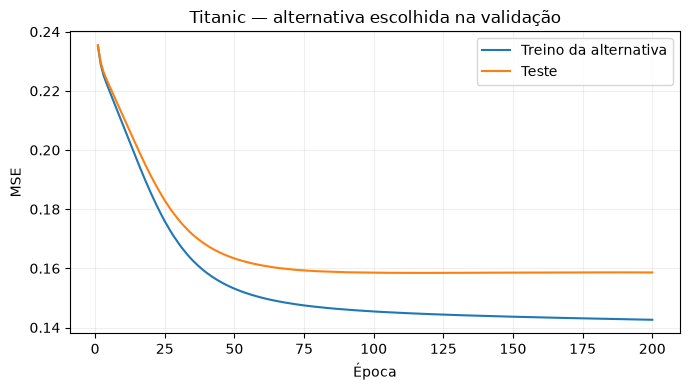

O ganho em acurácia deve ser interpretado junto à precisão e à revocação. Balanceamento não é uma melhoria automática: depende da métrica e dos custos dos erros. A alternativa preserva todos os parâmetros de treinamento pedidos; o experimento principal com balanceamento continua disponível para atender ao enunciado.


In [12]:
# Usei o Codex (OpenAI) como apoio nesta investigação adicional.
# Treinei novamente a alternativa escolhida usando todo o conjunto de treino.
np.random.seed(SEED)
grupos = [np.flatnonzero(y_treino == classe) for classe in [0, 1]]
if metodo_escolhido == 'Sem balanceamento':
    indices_final = np.arange(len(y_treino))
elif metodo_escolhido == 'Subamostragem':
    indices_final = np.concatenate([np.random.choice(g, min(map(len, grupos)), replace=False) for g in grupos])
else:
    indices_final = np.concatenate([np.concatenate([g, np.random.choice(
        g, max(map(len, grupos)) - len(g), replace=True)]) for g in grupos])
np.random.shuffle(indices_final)
rede_alternativa = RedeNeural(6, 8, eta=0.1, seed=SEED).fit(
    X_treino[indices_final], y_treino[indices_final], 200, 32, embaralhar=True,
    avaliacao=(X_teste, y_teste))
met_alternativa, matriz_alternativa = metricas(y_teste, rede_alternativa.predict(X_teste))
comparacao_final = pd.concat([resumo_titanic, pd.DataFrame([
    {'modelo': 'Rede 8 — ' + metodo_escolhido, **met_alternativa}])], ignore_index=True)
display(comparacao_final)
display(pd.DataFrame(matriz_alternativa, index=['Real 0', 'Real 1'], columns=['Previsto 0', 'Previsto 1']))
print('MSE final de teste (alternativa):', rede_alternativa.erro_teste[-1])
plt.plot(np.arange(1, 201), rede_alternativa.erro_treino, label='Treino da alternativa')
plt.plot(np.arange(1, 201), rede_alternativa.erro_teste, label='Teste')
plt.xlabel('Época'); plt.ylabel('MSE'); plt.title('Titanic — alternativa escolhida na validação')
plt.legend(); plt.tight_layout(); plt.show()
print('O ganho em acurácia deve ser interpretado junto à precisão e à revocação. '
      'Balanceamento não é uma melhoria automática: depende da métrica e dos custos dos erros. '
      'A alternativa preserva todos os parâmetros de treinamento pedidos; o experimento principal '
      'com balanceamento continua disponível para atender ao enunciado.')

## 7. Verificações e limites do experimento
As verificações automáticas confirmam a separação de AND/OR, a ausência de 100% no Perceptron em todas as épocas do XOR, a diferença de gradientes abaixo de 10⁻⁶, a ausência de interseção entre treino/teste, dados finitos e o orçamento de épocas. Os históricos completos permanecem em `modelo.historico`; os pesos são registrados após cada época. Os pesos iniciais ficam em `modelo.w_inicial`.

O experimento usa uma divisão de passageiros, não de famílias, e não estima intervalos de confiança. O balanceamento remove dados e pode alterar o compromisso entre precisão e revocação. Os resultados de 2, 8 e 32 unidades não justificam escolher uma largura pelo teste para implantação. A época sem erros é critério de parada apenas para o Perceptron; alcançar o limite de épocas não prova convergência.

## Conclusão (126 palavras)
O Perceptron aprendeu AND e OR porque essas funções admitem separação por uma reta. No XOR, variar a taxa de aprendizagem alterou a trajetória dos pesos, mas não removeu a limitação geométrica: classes em diagonais opostas não são linearmente separáveis. A rede com camada oculta e sigmoides conseguiu representar relações não lineares, enquanto o Backpropagation forneceu os gradientes para ajustar seus parâmetros. Entretanto, inicialização e saturação podem dificultar o treinamento, justificando a repetição com sementes diferentes. No Titanic, imputação, padronização e balanceamento foram estimados exclusivamente no treino, preservando o teste. As métricas e curvas permitem comparar a rede às referências sem presumir superioridade universal. Assim, capacidade de representação, qualidade dos dados e dinâmica de otimização devem ser analisadas conjuntamente, sem confundir limite de épocas com convergência.